# Acme Sports: trend analysis (100 weeks)

Five analyses required by the specification (section 7), run on all **100 weekly MRP runs** (Aug 2025 to Jun 2027),
as agreed with the client in the Week 2 review. Each analysis ends with how it connects to a buy-plan rule.

*Note:* factory utilisation in analyses 2 and 3 comes from `fact_factory_utilization` as delivered. The client is
reviewing records above 100%; the planning engine itself uses a rolling ledger built from its own assignments.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from engine.data_loader import load_data

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False})
d = load_data()
pr = d.prs.merge(d.runs[["run_id", "week_number"]], on="run_id")
so, fu, cust = d.sales_orders, d.utilization.copy(), d.customers.set_index("customer_id")
art = d.articles.set_index("article_id")
print(f"{len(pr):,} requisitions · {pr['requested_qty'].sum():,.0f} units · {len(so):,} sales orders · "
      f"{pr['week_number'].nunique()} weeks")

24,962 requisitions · 17,175,451 units · 17,669 sales orders · 100 weeks


## 1. Seasonal demand curve

### 1.1 Weekly demand and sales-order value

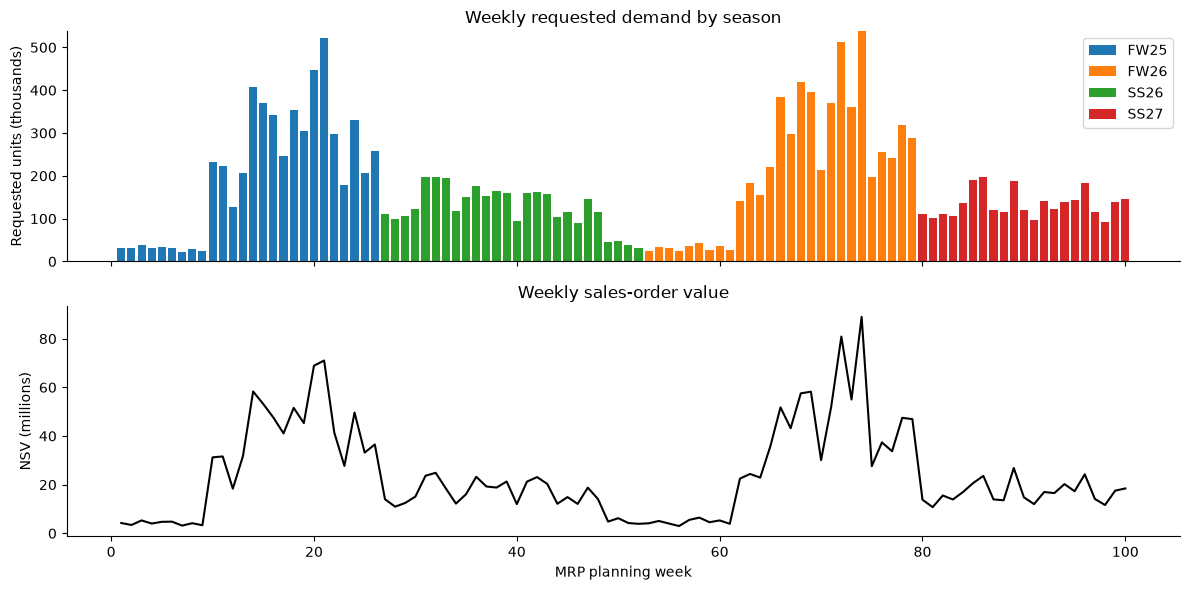

Highest-demand weeks:
week_number
74    537511
21    520801
72    513207


In [9]:
# Requested units by week and season
weekly = (
    pr.groupby(["week_number", "season"])["requested_qty"]
    .sum()
    .unstack(fill_value=0)
)

# Sales-order value linked to each PR's planning week
weekly_nsv = (
    so.merge(
        pr[["pr_id", "week_number"]],
        on="pr_id",
        validate="many_to_one"
    )
    .groupby("week_number")["net_sales_value"]
    .sum()
)

colors = {
    "FW25": "tab:blue",
    "FW26": "tab:orange",
    "SS26": "tab:green",
    "SS27": "tab:red"
}

fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)

bottom = np.zeros(len(weekly))
for season in weekly.columns:
    units = weekly[season] / 1_000
    axes[0].bar(
        weekly.index, units, bottom=bottom,
        color=colors[season], label=season
    )
    bottom += units.to_numpy()

axes[0].set_ylabel("Requested units (thousands)")
axes[0].set_title("Weekly requested demand by season")
axes[0].legend()

axes[1].plot(
    weekly_nsv.index, weekly_nsv / 1_000_000,
    color="black"
)
axes[1].set_ylabel("NSV (millions)")
axes[1].set_xlabel("MRP planning week")
axes[1].set_title("Weekly sales-order value")

plt.tight_layout()
plt.show()

print("Highest-demand weeks:")
print(weekly.sum(axis=1).nlargest(3).to_string())

Fall/Winter has higher demand peaks than Spring/Summer, while the periods between seasons show lower demand. The largest peak is week 74, with 537,511 requested units. Sales-order value broadly follows the demand peaks, although it covers only order-backed demand. These peaks indicate when to examine factory capacity and possible pull-forward into earlier buying windows. Factory-level checks are needed before recommending a move.

| Finding | Buy Plan rule | What the engine should do |
|---|---|---|
| FW demand has sharp peaks | Capacity-driven pull-forward | Check future factory loads. If overloaded, evaluate moving eligible demand into earlier buying windows with spare capacity. |
| Demand is lower between seasons | Factory capacity and certification | Check whether certified factories have available capacity in these earlier periods. Low demand alone does not prove spare capacity. |
| Requests appear in different planning weeks | Rule 1: release timing | Calculate purchase timing from each PR’s delivery date and manufacturing/transit lead times. Do not purchase everything immediately. |

### 1.2 Peak-to-trough ratio by market

In [10]:
# Weekly requested units for each market
market_weekly = (
    pr.groupby(["week_number", "market_destination"])["requested_qty"]
    .sum()
    .unstack(fill_value=0)
    .sort_index()
)

# Smooth demand using four complete weeks
rolling = market_weekly.rolling(window=4, min_periods=4).mean()

ratio = (
    rolling.max() / rolling.min()
).sort_values(ascending=False)

print("Peak-to-trough ratio (four-week average):")
print(ratio.round(1).to_string())

Peak-to-trough ratio (four-week average):
market_destination
MX    20.5
CL    20.5
BR    19.5
CO    18.3
AR    17.7
PE    16.3
US    15.4


Peak demand is approximately 15–21 times trough demand across the seven markets. Mexico and Chile show the largest relative swings. This supports checking capacity before high-demand periods and MOQ/MPQ compliance during quieter periods. The ratios measure demand variation, not market size; minimum quantities must still be checked for individual article–market groups.

| Finding | Buy Plan rule | What the engine should do |
|---|---|---|
| Market demand varies by approximately 15–21× | Rule 3: MOQ/MPQ | Check minimum quantities for actual article–market lots, especially during quieter periods. |
| Some lots may be too small | Rule 2: consolidation | Combine eligible requests for the same article and market within the permitted 15-day delivery-date span. |
| A lot may narrowly miss its minimum | Rule 4: piggybacking | Check the 5% shortfall condition before automatically bringing eligible future demand forward. |

## 2. Factory utilisation and backup trigger frequency

### 2.1 Which factories reach the threshold most often?

            weeks_observed  weeks_at_or_above_85  weeks_above_100
factory_id                                                       
ACME-BD02              100                    13                9
ACME-CN04              100                    79               78
ACME-ID03              100                    78               78
ACME-IN06              100                    34               29
ACME-TR05              100                    73               64
ACME-VN01              100                    78               78


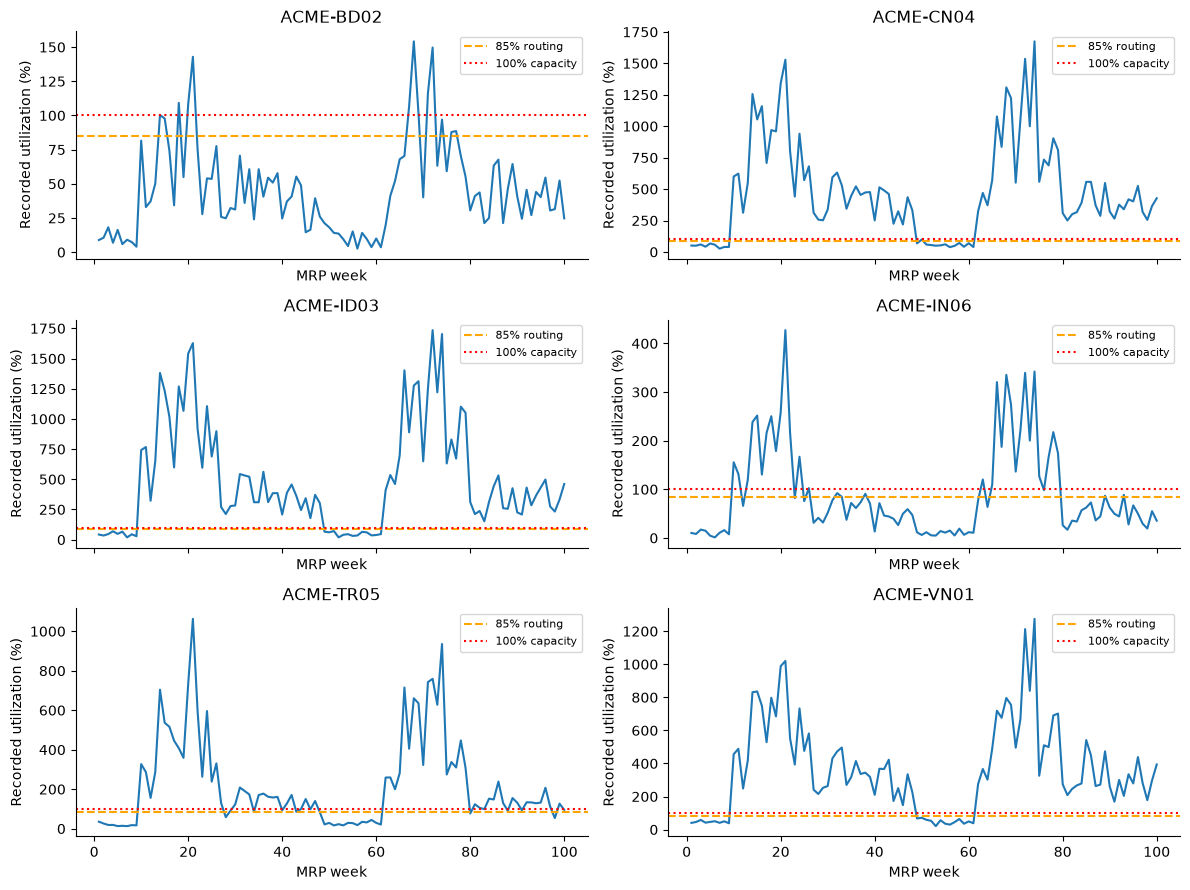

In [11]:
f = fu.copy()

f["at_85"] = f["utilization_pct"] >= 85
f["above_100"] = f["utilization_pct"] > 100

summary = f.groupby("factory_id").agg(
    weeks_observed=("run_id", "nunique"),
    weeks_at_or_above_85=("at_85", "sum"),
    weeks_above_100=("above_100", "sum")
)

print(summary.to_string())

# Separate charts make individual factories easier to inspect.
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharex=True)

for ax, (factory, data) in zip(
    axes.flat, f.groupby("factory_id")
):
    data = data.sort_values("week_number")

    ax.plot(data["week_number"], data["utilization_pct"])
    ax.axhline(85, color="orange", linestyle="--", label="85% routing")
    ax.axhline(100, color="red", linestyle=":", label="100% capacity")
    ax.set_title(factory)
    ax.set_ylabel("Recorded utilization (%)")
    ax.set_xlabel("MRP week")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

### 2.2 In which seasons?

In [12]:
season_percent = (
    f.groupby(["factory_id", "season"])["at_85"]
    .mean()
    .unstack()
    * 100
)

print("Percentage of weeks reaching 85%:")
print(season_percent.round(1).to_string())

print("\nObserved weeks per season:")
print(f.groupby("season")["run_id"].nunique().to_string())

Percentage of weeks reaching 85%:
season      FW25  FW26  SS26   SS27
factory_id                         
ACME-BD02   19.2  29.6   0.0    0.0
ACME-CN04   65.4  66.7  88.5  100.0
ACME-ID03   65.4  66.7  84.6  100.0
ACME-IN06   53.8  59.3   7.7    9.5
ACME-TR05   65.4  66.7  73.1   90.5
ACME-VN01   65.4  66.7  84.6  100.0

Observed weeks per season:
season
FW25    26
FW26    27
SS26    26
SS27    21


CN04, ID03 and VN01 reach the routing threshold in every observed SS27 week. BD02 remains below it throughout SS26 and SS27. Factory pressure therefore differs by factory and does not simply follow the overall FW demand peaks. Seasonal coverage also differs: SS27 contains 21 observed weeks, compared with 26–27 for the other seasons.

### 2.3 Is backup routing associated with utilization?

In [13]:
backup = (
    pr.groupby(["run_id", "primary_factory"])
    .agg(
        pr_count=("pr_id", "size"),
        backup_count=("backup_triggered", "sum")
    )
    .reset_index()
    .merge(
        f[["run_id", "factory_id", "utilization_pct", "at_85"]],
        left_on=["run_id", "primary_factory"],
        right_on=["run_id", "factory_id"],
        how="left",
        validate="one_to_one"
    )
)

assert backup["utilization_pct"].notna().all(), "Missing factory matches"

backup["backup_rate"] = backup["backup_count"] / backup["pr_count"]

rates = backup.groupby("at_85")[["pr_count", "backup_count"]].sum()
rates["backup_percent"] = (
    100 * rates["backup_count"] / rates["pr_count"]
)

print("Backup routing by primary-factory threshold status:")
print(rates.round(1).to_string())

correlation = backup["backup_rate"].corr(backup["utilization_pct"])
print(f"\nFactory-run correlation: {correlation:.2f}")

Backup routing by primary-factory threshold status:
       pr_count  backup_count  backup_percent
at_85                                        
False      4362             0             0.0
True      20600         14550            70.6

Factory-run correlation: 0.82


Backup routing is recorded for 70.6% of PRs associated with primary factories at or above 85%, compared with none below the threshold. The factory-run correlation is 0.82, showing a strong positive association in the supplied data. This does not prove that backup routing reduced overload or that our engine implements the rule correctly.

| Finding | Relevant rule | Planning implication |
|---|---|---|
| Some factories frequently reach 85% | Backup routing | Check projected primary load and certified backup availability before assigning additional demand. |
| Some factories have fewer threshold breaches | Factory certification | Investigate available capacity, but do not assume every article can use those factories. |
| Recorded loads often exceed 100% | Capacity-driven pull-forward | Investigate earlier production opportunities after confirming what the utilization data represents. |

## 3. Pull-forward opportunity map

### 3.1 Show busy and quiet fatory-weeks

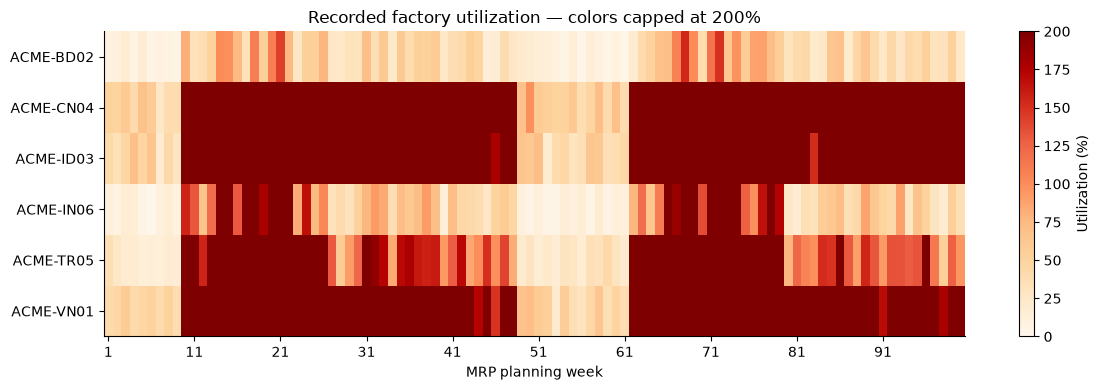

In [14]:
capacity = fu.pivot(
    index="factory_id",
    columns="week_number",
    values="utilization_pct"
).sort_index(axis=1)

fig, ax = plt.subplots(figsize=(12, 4))

image = ax.imshow(
    capacity,
    aspect="auto",
    cmap="OrRd",
    vmin=0,
    vmax=200
)

positions = list(range(0, len(capacity.columns), 10))
ax.set_xticks(positions)
ax.set_xticklabels(capacity.columns[positions])
ax.set_yticks(range(len(capacity.index)))
ax.set_yticklabels(capacity.index)

ax.set_xlabel("MRP planning week")
ax.set_title("Recorded factory utilization — colors capped at 200%")
fig.colorbar(image, ax=ax, label="Utilization (%)")

plt.tight_layout()
plt.show()

The heatmap identifies busy and quieter periods for each factory. Earlier low-utilization weeks are candidates for investigating pull-forward.

### 3.2 Estimate capacity without counting it twice

In [17]:
SOURCE_THRESHOLD = 85
QUIET_THRESHOLD = 60
DESTINATION_LIMIT = 85  # Assumption: confirm with client

rows = []

for factory, data in fu.sort_values("week_number").groupby("factory_id"):

    quiet = data[data["utilization_pct"] < QUIET_THRESHOLD]

    # Available capacity shared by all proposed moves.
    remaining = {
        int(r.week_number): max(
            0,
            DESTINATION_LIMIT / 100 * r.weekly_capacity - r.units_consumed
        )
        for r in quiet.itertuples()
    }

    busy = data[data["utilization_pct"] >= SOURCE_THRESHOLD]

    for r in busy.itertuples():
        earlier = quiet[quiet["week_number"] < r.week_number]

        if earlier.empty:
            target_week, quantity = None, 0
        else:
            target_week = int(earlier.iloc[-1]["week_number"])

            excess = max(
                0,
                r.units_consumed
                - SOURCE_THRESHOLD / 100 * r.weekly_capacity
            )

            quantity = min(excess, remaining[target_week])
            remaining[target_week] -= quantity

        rows.append({
            "factory": factory,
            "busy_week": r.week_number,
            "earlier_week": target_week,
            "capacity_estimate": quantity
        })

opportunities = pd.DataFrame(rows)

summary = opportunities.groupby("factory").agg(
    busy_weeks=("busy_week", "size"),
    with_earlier_week=("earlier_week", "count"),
    estimated_units=("capacity_estimate", "sum")
)

print(summary.round(0).to_string())
print(
    "\nTotal capacity-based estimate:",
    f"{opportunities['capacity_estimate'].sum():,.0f} units"
)

           busy_weeks  with_earlier_week  estimated_units
factory                                                  
ACME-BD02          13                 13          41662.0
ACME-CN04          79                 79          18211.0
ACME-ID03          78                 78          11516.0
ACME-IN06          34                 34          34040.0
ACME-TR05          73                 73          28582.0
ACME-VN01          78                 78          16785.0

Total capacity-based estimate: 150,796 units


Every busy factory-week has an earlier week below 60% utilization. Reserving that earlier capacity once produces an estimated 150,796 units of capacity-based opportunity, assuming an 85% destination ceiling. This is a retrospective estimate, not confirmed movable demand: individual PR eligibility, timing and minimum quantities still require validation.

### 3.3 Identify potential MOQ problems

In [16]:
requests = pr.merge(
    fu[["run_id", "factory_id", "utilization_pct"]],
    left_on=["run_id", "assigned_factory"],
    right_on=["run_id", "factory_id"],
    validate="many_to_one"
)

groups = (
    requests[requests["utilization_pct"] >= SOURCE_THRESHOLD]
    .groupby(["run_id", "factory_id", "article_id", "market_destination"])
    ["requested_qty"]
    .sum()
    .reset_index(name="units")
)

groups["below_moq"] = groups["units"] < 300

moq_summary = groups.groupby("market_destination").agg(
    groups_checked=("units", "size"),
    groups_below_moq=("below_moq", "sum")
)

moq_summary["below_moq_percent"] = (
    100 * moq_summary["groups_below_moq"]
    / moq_summary["groups_checked"]
)

print(moq_summary.round(1).to_string())

                    groups_checked  groups_below_moq  below_moq_percent
market_destination                                                     
AR                            1699               404               23.8
BR                            2358               487               20.7
CL                            1718               397               23.1
CO                            1892               406               21.5
MX                            2139               428               20.0
PE                            1480               396               26.8
US                            1904               478               25.1


Approximately 22.7% of these factory–article–market demand groups contain fewer than 300 units. This indicates potential minimum-quantity problems. These groups are not validated buying lots because buying-window and delivery-date grouping rules have not yet been applied.

| Finding | Business rule | Required check |
|---|---|---|
| Earlier quiet weeks exist | Capacity-driven pull-forward | Select eligible demand and reserve destination capacity once. |
| Some demand groups are small | MOQ/MPQ | Recalculate minimum quantities after each proposed move. |
| Demand is brought forward | Release timing and consolidation | Check earlier visibility, lead times and permitted delivery-date grouping. |